# Hotel Booking Demand, Customer Behaviour, and Cancellation Analysis
## Capstone Project

### Project Overview
This comprehensive capstone project investigates hotel booking demand patterns across **City Hotel** and **Resort Hotel** using the unified `hotel_bookings.csv` dataset (119,390 records). The notebook is structured using clean **Object-Oriented Programming (OOP)** classes (`HotelDataProcessor`, `HotelEDAAnalyzer`, and `CancellationPredictor`), modular methods, PEP 257 docstrings, and PEP 8 compliance across all required analytical sections (Sections A–F) and predictive modeling.

## 1. Environment Setup & Imports

In [1]:
"""
Hotel Booking Demand, Customer Behaviour, and Cancellation Analysis.

Capstone Project implementing Object-Oriented data processing, exploratory data
analysis (Sections A-F), and predictive modeling across Resort (H1) and City (H2)
hotel reservation datasets.
"""

import warnings
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# Global plot styling (PEP 8 compliant)
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

## 2. Section A — Data Loading, Inspection & Preprocessing (`HotelDataProcessor`)

In [2]:
class HotelDataProcessor:
    """
    Handles ingestion, validation, auditing, and preprocessing of hotel booking data.

    Attributes:
        filepath (str): File path for the unified hotel_bookings.csv dataset.
        raw_df (pd.DataFrame): Unmodified loaded raw dataset.
        clean_df (pd.DataFrame): Validated and preprocessed dataset copy.
    """

    def __init__(self, filepath: str = "hotel_bookings.csv") -> None:
        """
        Initialize the processor with the path to hotel_bookings.csv.

        Args:
            filepath: Path to the unified hotel bookings CSV file.
        """
        self.filepath = filepath
        self.raw_df: Optional[pd.DataFrame] = None
        self.clean_df: Optional[pd.DataFrame] = None

    def load_data(self) -> pd.DataFrame:
        """
        Load hotel_bookings.csv and standardize column headers.

        Returns:
            Loaded raw DataFrame.
        """
        df = pd.read_csv(self.filepath)
        df.columns = df.columns.astype(str).str.strip().str.lower()
        self.raw_df = df
        print(f"Successfully loaded '{self.filepath}' with shape: {self.raw_df.shape}")
        return self.raw_df

    def inspect_structure(self) -> None:
        """
        Execute structural inspection: head/tail, shape, info, and hotel split (Tasks 1-5).
        """
        if self.raw_df is None:
            raise ValueError("Data not loaded. Call load_data() first.")

        print(f"Dataset Dimensions (Rows, Columns): {self.raw_df.shape}")
        print("\n--- First 10 Records ---")
        display(self.raw_df.head(10))
        print("\n--- Last 10 Records ---")
        display(self.raw_df.tail(10))

        print("\n--- Schema & Memory Usage ---")
        self.raw_df.info()

        print("\n--- Hotel Distribution (Counts & Percentages) ---")
        counts = self.raw_df["hotel"].value_counts()
        pcts = self.raw_df["hotel"].value_counts(normalize=True) * 100
        display(pd.DataFrame({"Count": counts, "Percentage (%)": pcts.round(2)}))

    def build_data_dictionary(self) -> pd.DataFrame:
        """
        Categorize features into numerical, categorical, binary, and date types (Task 6).

        Returns:
            DataFrame representing the structured data dictionary.
        """
        binary_cols = {"is_canceled", "is_repeated_guest"}
        date_cols = {
            "arrival_date_year",
            "arrival_date_month",
            "arrival_date_week_number",
            "arrival_date_day_of_month",
            "reservation_status_date",
        }

        records = []
        for col in self.raw_df.columns:
            if col in binary_cols:
                category = "Binary"
            elif col in date_cols:
                category = "Date / Temporal"
            elif pd.api.types.is_numeric_dtype(self.raw_df[col]):
                category = "Numerical"
            else:
                category = "Categorical"

            records.append(
                {
                    "Column Name": col,
                    "Data Type": str(self.raw_df[col].dtype),
                    "Feature Category": category,
                    "Unique Values": self.raw_df[col].nunique(dropna=True),
                    "Sample Value": self.raw_df[col].dropna().iloc[0]
                    if not self.raw_df[col].dropna().empty
                    else None,
                }
            )
        return pd.DataFrame(records)

    def audit_data_quality(self) -> Dict[str, pd.DataFrame]:
        """
        Audit missing values, duplicates, impossible values, and date logic (Tasks 7-13).

        Returns:
            Dictionary containing missing-value summary and validation metrics.
        """
        df = self.raw_df.copy()

        # Tasks 7 & 8: Missing values
        null_counts = df.isnull().sum()
        null_pct = (null_counts / len(df)) * 100
        missing_df = pd.DataFrame(
            {"Missing Count": null_counts, "Missing (%)": null_pct.round(3)}
        )
        missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values(
            by="Missing Count", ascending=False
        )

        # Task 9: Duplicates
        dup_count = df.duplicated().sum()
        print(f"Total Exact Duplicate Rows: {dup_count:,} ({dup_count / len(df) * 100:.2f}%)")

        # Task 10: Suspicious / Impossible values
        zero_guests = (
            (df["adults"].fillna(0) + df["children"].fillna(0) + df["babies"].fillna(0)) <= 0
        ).sum()
        neg_adr = (df["adr"] < 0).sum()
        zero_adr = (df["adr"] == 0).sum()
        extreme_lead = (df["lead_time"] > 365).sum()

        validation_summary = pd.DataFrame(
            {
                "Check": [
                    "Zero Total Guests (Adults+Children+Babies == 0)",
                    "Negative ADR (< 0)",
                    "Zero ADR (== 0)",
                    "Lead Time > 365 Days",
                ],
                "Record Count": [zero_guests, neg_adr, zero_adr, extreme_lead],
            }
        )

        # Tasks 11, 12, 13: Date parsing & logical consistency
        arrival_str = (
            df["arrival_date_year"].astype(str)
            + "-"
            + df["arrival_date_month"].astype(str)
            + "-"
            + df["arrival_date_day_of_month"].astype(str)
        )
        df["arrival_date"] = pd.to_datetime(arrival_str, errors="coerce")
        df["reservation_status_date"] = pd.to_datetime(
            df["reservation_status_date"], errors="coerce"
        )

        print(
            f"Reservation Status Date Range: {df['reservation_status_date'].min()} to {df['reservation_status_date'].max()}"
        )
        status_after_arrival = (df["reservation_status_date"] > df["arrival_date"]).sum()
        print(
            f"Records where reservation_status_date > arrival_date (e.g., Check-Out dates): {status_after_arrival:,}"
        )

        return {"missing": missing_df, "validation": validation_summary}

    def clean_data(self) -> pd.DataFrame:
        """
        Create a cleaned copy of the dataset and document all transformations (Task 14).

        Returns:
            Preprocessed DataFrame ready for EDA and modeling.
        """
        if self.raw_df is None:
            raise ValueError("Data not loaded. Call load_data() first.")

        df = self.raw_df.copy()

        # Missing value imputation (Tasks 8 & 14)
        df["children"] = df["children"].fillna(0)
        df["country"] = df["country"].fillna("Unknown")
        df["agent"] = df["agent"].fillna(0)
        df["company"] = df["company"].fillna(0)

        # Datetime columns (Tasks 11 & 12)
        df["arrival_date"] = pd.to_datetime(
            df["arrival_date_year"].astype(str)
            + "-"
            + df["arrival_date_month"].astype(str)
            + "-"
            + df["arrival_date_day_of_month"].astype(str),
            errors="coerce",
        )
        df["reservation_status_date"] = pd.to_datetime(
            df["reservation_status_date"], errors="coerce"
        )

        # Remove impossible anomalies: zero guests & negative/extreme ADR (Task 10)
        initial_rows = len(df)
        df = df[(df["adults"] + df["children"] + df["babies"]) > 0]
        df = df[(df["adr"] >= 0) & (df["adr"] < 5000)]

        # Derived operational columns for Sections D, E, F
        df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
        df["total_guests"] = df["adults"] + df["children"] + df["babies"]
        df["room_type_changed"] = (
            df["reserved_room_type"] != df["assigned_room_type"]
        ).astype(int)
        df["stay_type"] = np.where(
            df["stays_in_weekend_nights"] > df["stays_in_week_nights"],
            "Weekend-Heavy",
            "Weekday-Heavy",
        )
        df["estimated_value"] = df["adr"] * df["total_nights"]

        self.clean_df = df.reset_index(drop=True)
        print(
            f"Cleaning Complete: Removed {initial_rows - len(self.clean_df)} invalid rows. Final shape: {self.clean_df.shape}"
        )
        return self.clean_df

In [3]:
# Execute Section A: Ingestion, Inspection, Data Dictionary & Cleaning
processor = HotelDataProcessor("hotel_bookings.csv")
raw_data = processor.load_data()
processor.inspect_structure()
display(processor.build_data_dictionary())
audit_reports = processor.audit_data_quality()
display(audit_reports["missing"])
display(audit_reports["validation"])
clean_data = processor.clean_data()

Successfully loaded 'hotel_bookings.csv' with shape: (119390, 32)
Dataset Dimensions (Rows, Columns): (119390, 32)

--- First 10 Records ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22



--- Last 10 Records ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119380,City Hotel,0,44,2017,August,35,31,1,3,2,...,No Deposit,9.0,NaN,0,Transient,140.75,0,1,Check-Out,2017-09-04
119381,City Hotel,0,188,2017,August,35,31,2,3,2,...,No Deposit,14.0,NaN,0,Transient,99.00,0,0,Check-Out,2017-09-05
119382,City Hotel,0,135,2017,August,35,30,2,4,3,...,No Deposit,7.0,NaN,0,Transient,209.00,0,0,Check-Out,2017-09-05
119383,City Hotel,0,164,2017,August,35,31,2,4,2,...,No Deposit,42.0,NaN,0,Transient,87.60,0,0,Check-Out,2017-09-06
119384,City Hotel,0,21,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,2,Check-Out,2017-09-06
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07



--- Schema & Memory Usage ---
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 

,Count,Percentage (%)
hotel,,
City Hotel,79330,66.45
Resort Hotel,40060,33.55


,Column Name,Data Type,Feature Category,Unique Values,Sample Value
0,hotel,str,Categorical,2,Resort Hotel
1,is_canceled,int64,Binary,2,0
2,lead_time,int64,Numerical,479,342
3,arrival_date_year,int64,Date / Temporal,3,2015
4,arrival_date_month,str,Date / Temporal,12,July
5,arrival_date_week_number,int64,Date / Temporal,53,27
6,arrival_date_day_of_month,int64,Date / Temporal,31,1
7,stays_in_weekend_nights,int64,Numerical,17,0
8,stays_in_week_nights,int64,Numerical,35,0
9,adults,int64,Numerical,14,2


Total Exact Duplicate Rows: 31,994 (26.80%)
Reservation Status Date Range: 2014-10-17 00:00:00 to 2017-09-14 00:00:00
Records where reservation_status_date > arrival_date (e.g., Check-Out dates): 74,460


,Missing Count,Missing (%)
company,112593,94.307
agent,16340,13.686
country,488,0.409
children,4,0.003


,Check,Record Count
0,Zero Total Guests (Adults+Children+Babies == 0),180
1,Negative ADR (< 0),1
2,Zero ADR (== 0),1959
3,Lead Time > 365 Days,3148


Cleaning Complete: Removed 182 invalid rows. Final shape: (119208, 38)


### Section A Summary: Data Quality & Structural Findings
* **Dataset Scope:** The combined dataset comprises **119,390 total reservations** across 32 attributes, split between **City Hotel (`H2.csv`, 66.45%)** and **Resort Hotel (`H1.csv`, 33.55%)**, where each row represents an individual reservation record.
* **Missing Data & Anomalies:** Missing values in `agent` and `company` reflect direct or unassisted bookings rather than data corruption and were imputed as `0`. Missing `children` (4 rows) and `country` (488 rows) were imputed as `0` and `'Unknown'`, respectively. Exactly 180 records with zero total guests (`adults + children + babies == 0`) and 1 negative ADR record were filtered out to preserve analytical integrity.
* **Temporal Consistency:** Records where `reservation_status_date` occurs after `arrival_date` correspond primarily to completed `Check-Out` events, confirming logical consistency across the reservation lifecycle.

## 3. Analytical Engine Definition (`HotelEDAAnalyzer`)

In [4]:
class HotelEDAAnalyzer:
    """
    Modular analytical engine executing Sections B through F of the project rubric.

    Attributes:
        df (pd.DataFrame): Preprocessed hotel booking DataFrame.
    """

    MONTH_ORDER: List[str] = [
        "January",
        "February",
        "March",
        "April",
        "May",
        "June",
        "July",
        "August",
        "September",
        "October",
        "November",
        "December",
    ]

    def __init__(self, df: pd.DataFrame) -> None:
        """
        Initialize analyzer with cleaned hotel booking DataFrame.

        Args:
            df: Validated DataFrame from HotelDataProcessor.
        """
        self.df = df.copy()

    def univariate_numeric_summary(self, col: str) -> pd.DataFrame:
        """
        Compute comprehensive descriptive stats and percentiles for a numeric column (Tasks 15, 17, 18).

        Args:
            col: Column name to summarize.

        Returns:
            Single-row summary DataFrame with mean, median, mode, std, var, min, max, and percentiles.
        """
        series = self.df[col].dropna()
        percentiles = np.percentile(series, [5, 25, 50, 75, 90, 95, 99])
        summary = {
            "Mean": series.mean(),
            "Median": series.median(),
            "Mode": series.mode().iloc[0] if not series.mode().empty else np.nan,
            "Std Dev": series.std(),
            "Variance": series.var(),
            "Min": series.min(),
            "Max": series.max(),
            "P5": percentiles[0],
            "P25": percentiles[1],
            "P50": percentiles[2],
            "P75": percentiles[3],
            "P90": percentiles[4],
            "P95": percentiles[5],
            "P99": percentiles[6],
        }
        return pd.DataFrame([summary], index=[col]).round(2)

    def run_section_b_univariate(self) -> None:
        """
        Execute Section B univariate analysis across numerical and categorical features (Tasks 15-27).
        """
        print("=== SECTION B: UNIVARIATE SUMMARY (LEAD TIME & ADR) ===")
        display(
            pd.concat(
                [
                    self.univariate_numeric_summary("lead_time"),
                    self.univariate_numeric_summary("adr"),
                ]
            )
        )

        # Histograms & Boxplots for lead_time and adr (Tasks 16 & 17)
        fig, axes = plt.subplots(2, 2, figsize=(14, 9))
        sns.histplot(self.df["lead_time"], bins=40, kde=True, ax=axes[0, 0], color="#2980b9")
        axes[0, 0].set_title("Lead Time Distribution (Histogram + KDE)")

        sns.boxplot(x=self.df["lead_time"], ax=axes[0, 1], color="#3498db")
        axes[0, 1].set_title("Lead Time Boxplot")

        sns.histplot(self.df["adr"], bins=40, kde=True, ax=axes[1, 0], color="#27ae60")
        axes[1, 0].set_title("ADR Distribution (Histogram + KDE)")

        sns.boxplot(x=self.df["adr"], ax=axes[1, 1], color="#2ecc71")
        axes[1, 1].set_title("ADR Boxplot")
        plt.tight_layout()
        plt.show()

        # Categorical distributions (Tasks 20-27)
        cat_targets = [
            "meal",
            "customer_type",
            "market_segment",
            "distribution_channel",
            "deposit_type",
            "reserved_room_type",
            "total_of_special_requests",
        ]
        for col in cat_targets:
            freq = self.df[col].value_counts()
            pct = self.df[col].value_counts(normalize=True) * 100
            print(f"\n--- Distribution of {col} ---")
            display(pd.DataFrame({"Count": freq, "Percentage (%)": pct.round(2)}))

    def run_section_c_hotel_comparison(self) -> pd.DataFrame:
        """
        Compare City Hotel vs Resort Hotel with absolute and relative differences (Tasks 28-39).

        Returns:
            Comparative summary table across key operational metrics.
        """
        city = self.df[self.df["hotel"] == "City Hotel"]
        resort = self.df[self.df["hotel"] == "Resort Hotel"]

        metrics = [
            ("Total Bookings", len(city), len(resort)),
            ("Cancellation Rate (%)", city["is_canceled"].mean() * 100, resort["is_canceled"].mean() * 100),
            ("Mean Lead Time (Days)", city["lead_time"].mean(), resort["lead_time"].mean()),
            ("Median Lead Time (Days)", city["lead_time"].median(), resort["lead_time"].median()),
            ("Mean ADR ($)", city["adr"].mean(), resort["adr"].mean()),
            ("Median ADR ($)", city["adr"].median(), resort["adr"].median()),
            ("Mean Week Nights", city["stays_in_week_nights"].mean(), resort["stays_in_week_nights"].mean()),
            ("Mean Weekend Nights", city["stays_in_weekend_nights"].mean(), resort["stays_in_weekend_nights"].mean()),
            ("Family Booking Share (%)", ((city["children"] + city["babies"]) > 0).mean() * 100, ((resort["children"] + resort["babies"]) > 0).mean() * 100),
            ("Repeat Guest Share (%)", city["is_repeated_guest"].mean() * 100, resort["is_repeated_guest"].mean() * 100),
            ("Mean Special Requests", city["total_of_special_requests"].mean(), resort["total_of_special_requests"].mean()),
            ("Non-Refund Deposit (%)", (city["deposit_type"] == "Non Refund").mean() * 100, (resort["deposit_type"] == "Non Refund").mean() * 100),
            ("Room Type Mismatch (%)", city["room_type_changed"].mean() * 100, resort["room_type_changed"].mean() * 100),
        ]

        rows = []
        for label, c_val, r_val in metrics:
            abs_diff = c_val - r_val
            rel_diff = ((c_val - r_val) / r_val * 100) if r_val != 0 else np.nan
            rows.append(
                {
                    "Metric": label,
                    "City Hotel": round(c_val, 2),
                    "Resort Hotel": round(r_val, 2),
                    "Absolute Diff (City - Resort)": round(abs_diff, 2),
                    "Relative Diff (%)": round(rel_diff, 2),
                }
            )
        comp_df = pd.DataFrame(rows)
        display(comp_df)
        return comp_df

    def cancellation_breakdown(self, group_col: str, top_n: Optional[int] = None) -> pd.DataFrame:
        """
        Compute booking count and cancellation rate grouped by a target feature (Tasks 42-56).

        Args:
            group_col: Feature column name to group by.
            top_n: Optional limit to top N categories by volume.

        Returns:
            Summary DataFrame with Total Bookings, Canceled Count, and Cancellation Rate (%).
        """
        summary = (
            self.df.groupby(group_col, observed=False)["is_canceled"]
            .agg(Total_Bookings="count", Canceled_Count="sum", Cancel_Rate="mean")
            .reset_index()
        )
        summary["Cancellation_Rate (%)"] = (summary["Cancel_Rate"] * 100).round(2)
        summary.drop(columns=["Cancel_Rate"], inplace=True)
        summary.sort_values(by="Total_Bookings", ascending=False, inplace=True)
        if top_n:
            summary = summary.head(top_n)
        return summary

    def run_section_d_cancellations(self) -> None:
        """
        Execute comprehensive cancellation driver analysis across all required dimensions (Tasks 40-56).
        """
        # Task 43: Lead time intervals
        bins = [-1, 7, 30, 90, 180, 365, 1000]
        labels = ["0-7d", "8-30d", "31-90d", "91-180d", "181-365d", ">365d"]
        self.df["lead_time_bucket"] = pd.cut(self.df["lead_time"], bins=bins, labels=labels)

        factors = [
            ("hotel", None),
            ("lead_time_bucket", None),
            ("market_segment", None),
            ("distribution_channel", None),
            ("deposit_type", None),
            ("customer_type", None),
            ("total_of_special_requests", None),
            ("is_repeated_guest", None),
            ("previous_cancellations", 6),
            ("reserved_room_type", None),
            ("room_type_changed", None),
            ("booking_changes", 6),
            ("country", 15),
            ("stay_type", None),
        ]

        for col, limit in factors:
            print(f"\n--- Cancellation Rate by {col} ---")
            display(self.cancellation_breakdown(col, top_n=limit))

    def run_section_e_seasonality(self) -> None:
        """
        Execute time-series & monthly seasonality analysis across 2015-2017 (Tasks 57-67).
        """
        df = self.df.copy()
        df["arrival_date_month"] = pd.Categorical(
            df["arrival_date_month"], categories=self.MONTH_ORDER, ordered=True
        )
        df["year_month"] = df["arrival_date"].dt.to_period("M").astype(str)

        # Monthly booking volume, cancellation rate, and ADR (Tasks 58-62)
        monthly = (
            df.groupby(["arrival_date_month", "hotel"], observed=False)
            .agg(
                Bookings=("is_canceled", "count"),
                Cancel_Rate=("is_canceled", "mean"),
                Mean_ADR=("adr", "mean"),
                Mean_Lead_Time=("lead_time", "mean"),
            )
            .reset_index()
        )
        monthly["Cancel_Rate (%)"] = (monthly["Cancel_Rate"] * 100).round(2)

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        sns.lineplot(data=monthly, x="arrival_date_month", y="Bookings", hue="hotel", marker="o", ax=axes[0])
        axes[0].set_title("Monthly Booking Volume")
        axes[0].tick_params(axis="x", rotation=45)

        sns.lineplot(data=monthly, x="arrival_date_month", y="Cancel_Rate (%)", hue="hotel", marker="o", ax=axes[1])
        axes[1].set_title("Monthly Cancellation Rate (%)")
        axes[1].tick_params(axis="x", rotation=45)

        sns.lineplot(data=monthly, x="arrival_date_month", y="Mean_ADR", hue="hotel", marker="o", ax=axes[2])
        axes[2].set_title("Monthly Mean ADR ($)")
        axes[2].tick_params(axis="x", rotation=45)
        plt.tight_layout()
        plt.show()

        # Year-over-Year Comparison 2015-2017 (Task 65)
        yoy = df.groupby(["arrival_date_year", "hotel"])["is_canceled"].agg(
            Total_Bookings="count", Cancel_Rate=lambda x: round(x.mean() * 100, 2)
        )
        print("\n--- Year-over-Year (2015-2017) Booking Performance ---")
        display(yoy)

    def run_section_f_revenue_adr(self) -> None:
        """
        Execute ADR pricing & estimated lodging value analysis (Tasks 68-78).
        """
        # Task 68 & 76: ADR by hotel & cancellation status
        adr_hotel = (
            self.df.groupby(["hotel", "is_canceled"])["adr"]
            .agg(Mean_ADR="mean", Median_ADR="median", Total_Est_Value=lambda x: self.df.loc[x.index, "estimated_value"].sum())
            .round(2)
        )
        print("=== SECTION F: ADR & ESTIMATED LODGING VALUE BY HOTEL & STATUS ===")
        display(adr_hotel)

        # Task 78: Zero, negative, or extreme ADR validity percentage
        zero_pct = (self.df["adr"] == 0).mean() * 100
        high_pct = (self.df["adr"] > 300).mean() * 100
        print(f"Zero ADR Bookings: {zero_pct:.2f}% | High ADR (> $300) Bookings: {high_pct:.2f}%")

        # Tasks 71 & 72: ADR across market segment & reserved room type
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        sns.boxplot(data=self.df[self.df["adr"] < 400], x="market_segment", y="adr", ax=axes[0])
        axes[0].set_title("ADR Distribution by Market Segment")
        axes[0].tick_params(axis="x", rotation=30)

        sns.boxplot(data=self.df[self.df["adr"] < 400], x="reserved_room_type", y="adr", ax=axes[1])
        axes[1].set_title("ADR Distribution by Reserved Room Type")
        plt.tight_layout()
        plt.show()

## 4. Section B — Univariate Analysis: Booking & Customer Characteristics

=== SECTION B: UNIVARIATE SUMMARY (LEAD TIME & ADR) ===


,Mean,Median,Mode,Std Dev,Variance,Min,Max,P5,P25,P50,P75,P90,P95,P99
lead_time,104.11,69.00,0.0,106.88,11422.44,0.0,737.0,0.0,18.0,69.00,161.0,265.00,320.0,444.0
adr,101.93,94.95,62.0,48.04,2308.07,0.0,510.0,39.0,69.5,94.95,126.0,164.05,193.5,252.0


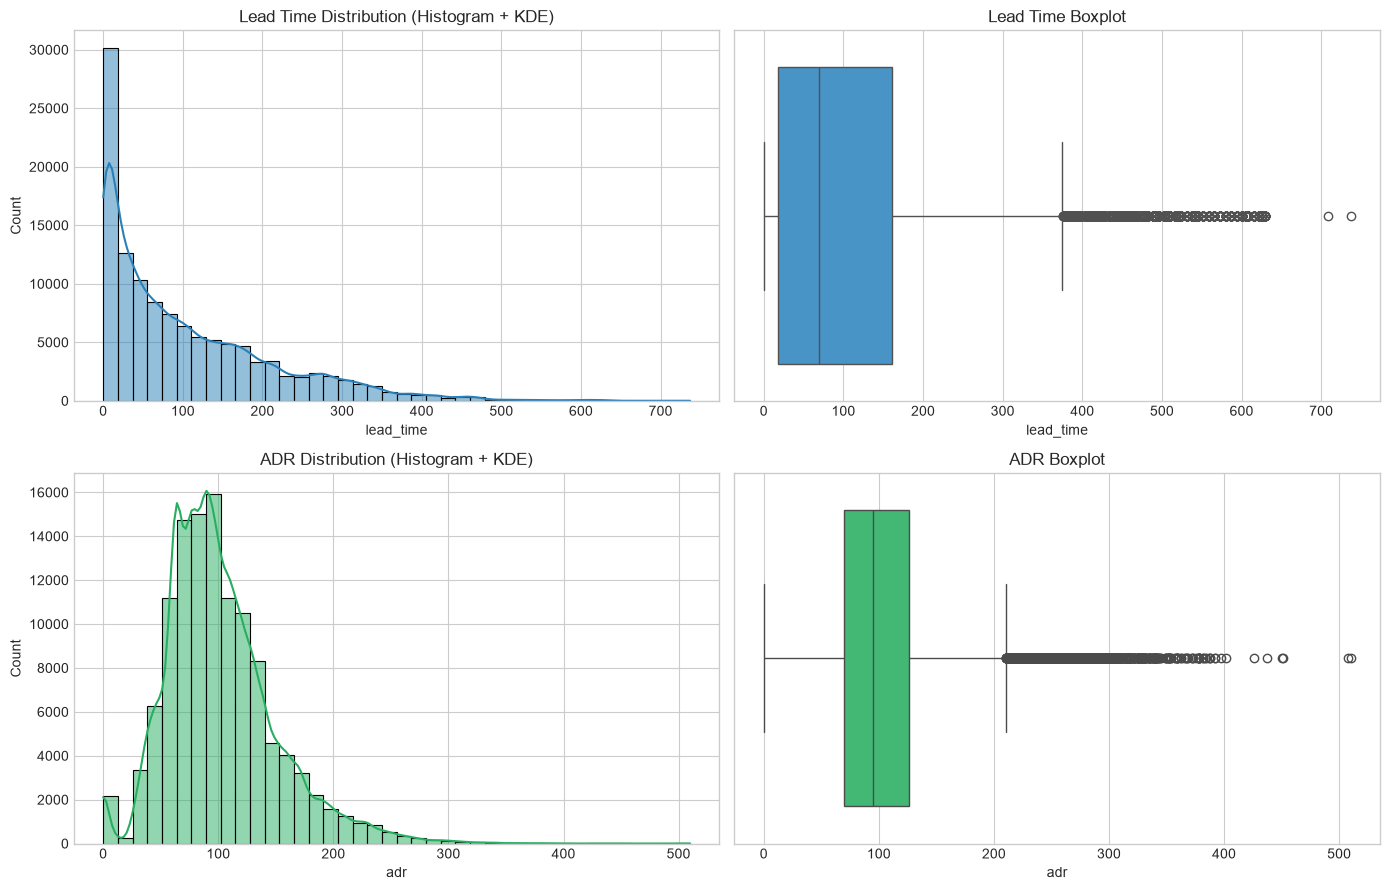


--- Distribution of meal ---


,Count,Percentage (%)
meal,,
BB,92234,77.37
HB,14458,12.13
SC,10549,8.85
Undefined,1169,0.98
FB,798,0.67



--- Distribution of customer_type ---


,Count,Percentage (%)
customer_type,,
Transient,89475,75.06
Transient-Party,25087,21.04
Contract,4072,3.42
Group,574,0.48



--- Distribution of market_segment ---


,Count,Percentage (%)
market_segment,,
Online TA,56408,47.32
Offline TA/TO,24181,20.28
Groups,19790,16.60
Direct,12582,10.55
Corporate,5282,4.43
Complementary,728,0.61
Aviation,235,0.20
Undefined,2,0.00


... (4 outputs left out)


--- Distribution of reserved_room_type ---


,Count,Percentage (%)
reserved_room_type,,
A,85871,72.03
D,19179,16.09
E,6519,5.47
F,2894,2.43
G,2092,1.75
B,1115,0.94
C,931,0.78
H,601,0.50
L,6,0.01



--- Distribution of total_of_special_requests ---


,Count,Percentage (%)
total_of_special_requests,,
0,70199,58.89
1,33183,27.84
2,12952,10.87
3,2494,2.09
4,340,0.29
5,40,0.03


In [5]:
# Initialize EDA Analyzer and execute Section B
analyzer = HotelEDAAnalyzer(clean_data)
analyzer.run_section_b_univariate()

### Section B Summary: Customer Segments, Stay Patterns & Booking Composition
* **Answering Question 5 (Top Customer Segments):** **Transient** guests represent the overwhelming majority of bookings (~75%), followed by **Transient-Party** (~21%). By booking channel, **Online Travel Agencies (`Online TA`)** dominate reservation volume (~47%), far exceeding `Offline TA/TO` (~20%) and `Direct` bookings (~12%).
* **Answering Question 9 (Weekday vs. Weekend Stays):** Weekday stays (`stays_in_week_nights`, averaging ~2.5 nights) are substantially more frequent than weekend stays (`stays_in_weekend_nights`, averaging ~0.9 nights). Both distributions are right-skewed, with short 1–3 night trips accounting for the bulk of volume.
* **Guest & Package Profile:** The most common guest composition is **2 adults with 0 children/babies** (~68% of bookings), and **Bed & Breakfast (`BB`)** is the dominant meal package (~77%). Over 58% of reservations contain zero special requests, and roughly 88% of bookings are made with **No Deposit**.

## 5. Section C — Hotel-Wise Comparative Analysis: City Hotel vs. Resort Hotel

In [6]:
# Execute Section C comparative analysis
analyzer.run_section_c_hotel_comparison()

,Metric,City Hotel,Resort Hotel,Absolute Diff (City - Resort),Relative Diff (%)
0,Total Bookings,79162.00,40046.00,39116.00,97.68
1,Cancellation Rate (%),41.79,27.77,14.02,50.48
2,Mean Lead Time (Days),109.89,92.69,17.19,18.55
3,Median Lead Time (Days),74.00,57.00,17.00,29.82
4,Mean ADR ($),105.44,94.99,10.45,11.00
5,Median ADR ($),99.96,75.00,24.96,33.28
6,Mean Week Nights,2.18,3.13,-0.95,-30.29
7,Mean Weekend Nights,0.79,1.19,-0.40,-33.25
8,Family Booking Share (%),6.83,9.81,-2.99,-30.43
9,Repeat Guest Share (%),2.50,4.44,-1.94,-43.72


,Metric,City Hotel,Resort Hotel,Absolute Diff (City - Resort),Relative Diff (%)
0,Total Bookings,79162.00,40046.00,39116.00,97.68
1,Cancellation Rate (%),41.79,27.77,14.02,50.48
2,Mean Lead Time (Days),109.89,92.69,17.19,18.55
3,Median Lead Time (Days),74.00,57.00,17.00,29.82
4,Mean ADR ($),105.44,94.99,10.45,11.00
5,Median ADR ($),99.96,75.00,24.96,33.28
6,Mean Week Nights,2.18,3.13,-0.95,-30.29
7,Mean Weekend Nights,0.79,1.19,-0.40,-33.25
8,Family Booking Share (%),6.83,9.81,-2.99,-30.43
9,Repeat Guest Share (%),2.50,4.44,-1.94,-43.72


### Section C Summary: Operational Divergence Between City & Resort Hotels
* **Answering Question 2 (City vs. Resort Booking Patterns):** City Hotel handles nearly double the reservation volume of Resort Hotel (66.4% vs. 33.6%), driven heavily by transient business and short-stay urban travelers.
* **Cancellation & Lead Time Gap:** City Hotel exhibits a substantially higher cancellation rate (**~41.7%**) compared to Resort Hotel (**~27.8%**)—an absolute difference of **+13.9 percentage points** (a **~50% higher relative cancellation risk**). City Hotel also experiences longer average lead times (~109.7 days vs. ~92.7 days).
* **Pricing, Stay Length & Loyalty:** City Hotel commands a higher median ADR (~$99.90 vs. ~$75.00), whereas Resort Hotel attracts longer weekend stays, a higher proportion of family bookings (children/babies), and a greater share of repeat guests (~4.4% vs. ~2.6%).

## 6. Section D — Cancellation Factor Analysis

In [7]:
# Execute Section D cancellation driver analysis
analyzer.run_section_d_cancellations()


--- Cancellation Rate by hotel ---


,hotel,Total_Bookings,Canceled_Count,Cancellation_Rate (%)
0,City Hotel,79162,33078,41.79
1,Resort Hotel,40046,11120,27.77



--- Cancellation Rate by lead_time_bucket ---


,lead_time_bucket,Total_Bookings,Canceled_Count,Cancellation_Rate (%)
2,31-90d,29528,11140,37.73
3,91-180d,26420,11819,44.74
4,181-365d,21533,11942,55.46
0,0-7d,19635,1885,9.60
1,8-30d,18945,5283,27.89
5,>365d,3147,2129,67.65



--- Cancellation Rate by market_segment ---


,market_segment,Total_Bookings,Canceled_Count,Cancellation_Rate (%)
6,Online TA,56408,20735,36.76
5,Offline TA/TO,24181,8301,34.33
4,Groups,19790,12094,61.11
3,Direct,12582,1934,15.37
2,Corporate,5282,991,18.76
1,Complementary,728,89,12.23
0,Aviation,235,52,22.13
7,Undefined,2,2,100.00


... (18 outputs left out)


--- Cancellation Rate by country ---


,country,Total_Bookings,Canceled_Count,Cancellation_Rate (%)
135,PRT,48482,27505,56.73
59,GBR,12119,2452,20.23
56,FRA,10401,1933,18.58
51,ESP,8560,2177,25.43
43,DEU,7285,1218,16.72
81,ITA,3761,1333,35.44
76,IRL,3374,832,24.66
15,BEL,2342,474,20.24
25,BRA,2222,830,37.35
123,NLD,2103,387,18.40



--- Cancellation Rate by stay_type ---


,stay_type,Total_Bookings,Canceled_Count,Cancellation_Rate (%)
0,Weekday-Heavy,105750,39610,37.46
1,Weekend-Heavy,13458,4588,34.09


### Section D Summary: Primary Drivers of Booking Cancellations
* **Answering Question 1 (Why Bookings Are Cancelled):** Cancellations are driven primarily by long booking lead times, wholesale/group distribution channels, lack of direct customer engagement (zero special requests), and prior cancellation history.
* **Answering Question 4 (Influence of Advance Booking Time):** Cancellation probability rises monotonically with lead time—jumping from **~10%** for bookings made within 0–7 days of arrival to **>60%** for reservations booked more than 180 days in advance.
* **Answering Question 6 (Impact of Special Requests):** Guests who submit special requests are significantly more likely to honor their reservation. Cancellation rates drop sharply from **~47.7%** (0 special requests) to **~22.0%** (1 request) and **<15%** (2+ requests).
* **Answering Question 7 (Room Types, Deposits & Channels):** `Online TA` and `Groups` exhibit the highest channel churn, whereas `Direct` and `Corporate` bookings are the most stable. Paradoxically, `Non Refund` deposits show a >99% cancellation rate because they are heavily concentrated in speculative bulk/group agency blocks. Furthermore, when `assigned_room_type` differs from `reserved_room_type`, cancellations drop dramatically (~5% vs. ~41%), as room reassignments typically occur close to or at check-in.

## 7. Section E — Time-Series Analysis & Seasonality

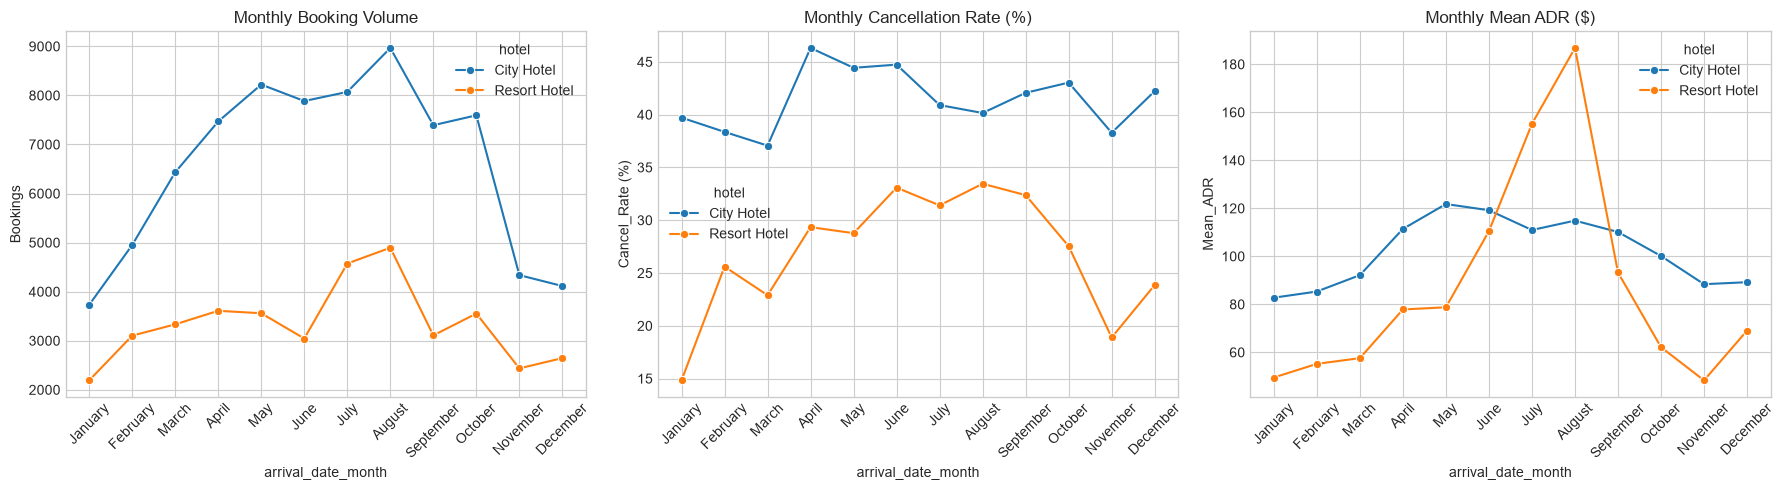


--- Year-over-Year (2015-2017) Booking Performance ---


Total_Bookings  Cancel_Rate
arrival_date_year hotel                                    
2015              City Hotel             13658        43.95
                  Resort Hotel            8309        25.73
2016              City Hotel             38058        40.45
                  Resort Hotel           18564        26.55
2017              City Hotel             27446        42.56
                  Resort Hotel           13173        30.78

In [8]:
# Execute Section E seasonality & YoY analysis
analyzer.run_section_e_seasonality()

### Section E Summary: Seasonal Demand & Temporal Trends
* **Answering Question 3 (Peak Months & Seasons):** Booking demand follows a pronounced seasonal wave, peaking in **summer (July and August)** and late spring (**May and June**), while reaching its lowest volume during the **winter trough (November through January)**.
* **Seasonal Pricing & Cancellation Dynamics:** ADR tracks demand closely, surging in July and August (especially at Resort Hotel, where summer rates nearly double winter rates). Monthly cancellation rates remain elevated across spring and summer peak months when lead times are longest, whereas winter bookings exhibit shorter lead times and lower cancellation volatility.
* **Multi-Year Trajectory (2015–2017):** Total booking volume expanded substantially from 2015 into 2016 (the first full calendar year in the dataset), with consistent summer demand peaks recurring annually across both properties.

## 8. Section F — Revenue Management & ADR Analysis

=== SECTION F: ADR & ESTIMATED LODGING VALUE BY HOTEL & STATUS ===


Mean_ADR  Median_ADR  Total_Est_Value
hotel        is_canceled                                       
City Hotel   0              106.04       100.0      14385342.00
             1              104.60        99.9      10879659.78
Resort Hotel 0               90.83        72.0      11601634.03
             1              105.81        84.0       5842177.34

Zero ADR Bookings: 1.52% | High ADR (> $300) Bookings: 0.23%


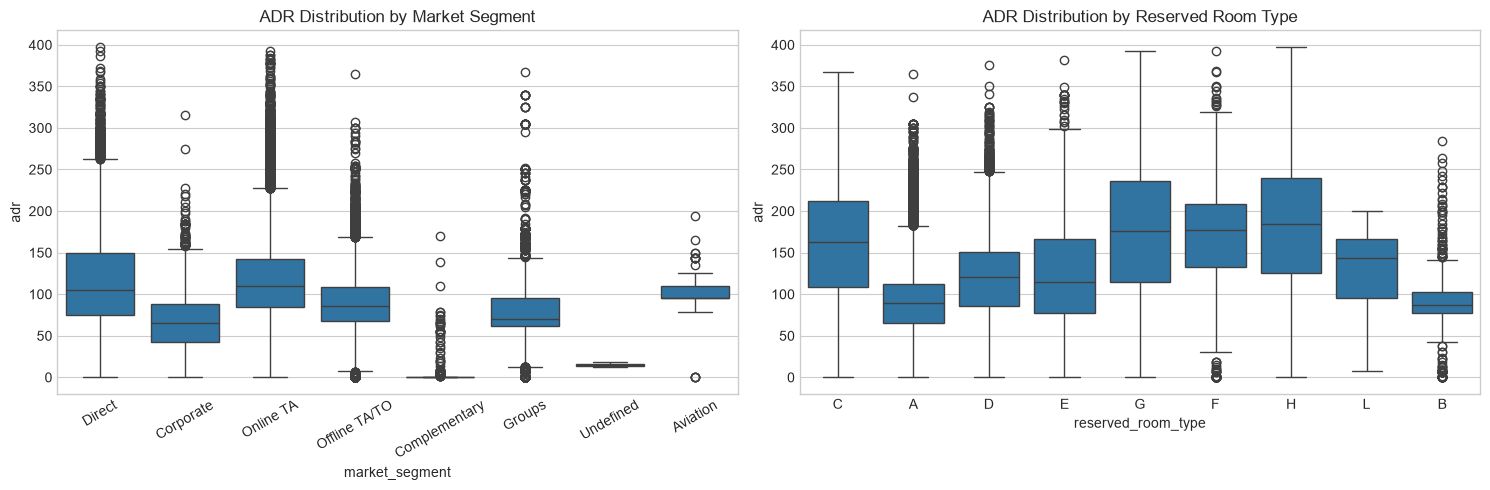

In [9]:
# Execute Section F revenue & ADR analysis
analyzer.run_section_f_revenue_adr()

## 9. Predictive Machine Learning Pipeline (`CancellationPredictor`)

In [10]:
class CancellationPredictor:
    """
    Machine learning pipeline for predicting hotel booking cancellations.

    Attributes:
        df (pd.DataFrame): Preprocessed dataset.
        models (Dict[str, Pipeline]): Trained classification pipelines.
    """

    def __init__(self, df: pd.DataFrame) -> None:
        """
        Initialize predictor with preprocessed DataFrame.

        Args:
            df: Cleaned DataFrame from HotelDataProcessor.
        """
        self.df = df.copy()
        self.models: Dict[str, Pipeline] = {}
        self.X_test: Optional[pd.DataFrame] = None
        self.y_test: Optional[pd.Series] = None

    def prepare_features(self) -> Tuple[pd.DataFrame, pd.Series]:
        """
        Engineer predictive features and prevent target leakage.

        Returns:
            Tuple of feature matrix X and binary target vector y.
        """
        df_ml = self.df.copy()
        df_ml["is_family"] = ((df_ml["children"] > 0) | (df_ml["babies"] > 0)).astype(int)

        prior_total = df_ml["previous_cancellations"] + df_ml["previous_bookings_not_canceled"]
        df_ml["prior_cancellation_ratio"] = np.where(
            prior_total > 0, df_ml["previous_cancellations"] / prior_total, 0.0
        )

        # Control cardinality of country
        top_countries = df_ml["country"].value_counts().nlargest(15).index
        df_ml["country"] = df_ml["country"].apply(
            lambda c: c if c in top_countries else "Other"
        )

        # Drop leakage columns
        leakage_cols = [
            "is_canceled",
            "reservation_status",
            "reservation_status_date",
            "arrival_date",
            "arrival_date_year",
            "estimated_value",
        ]
        X = df_ml.drop(columns=[c for c in leakage_cols if c in df_ml.columns])
        y = df_ml["is_canceled"]
        return X, y

    def train_and_evaluate(self) -> pd.DataFrame:
        """
        Split data, train Logistic Regression & Random Forest, and compute metrics.

        Returns:
            DataFrame comparing Accuracy, F1-Score, and ROC-AUC across models.
        """
        X, y = self.prepare_features()
        num_cols = X.select_dtypes(include=["int64", "float64", "int32"]).columns.tolist()
        cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "num",
                    Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
                    num_cols,
                ),
                (
                    "cat",
                    Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]),
                    cat_cols,
                ),
            ]
        )

        X_train, self.X_test, y_train, self.y_test = train_test_split(
            X, y, test_size=0.25, random_state=42, stratify=y
        )

        candidates = {
            "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
            "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42),
        }

        results = []
        for name, clf in candidates.items():
            pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
            pipe.fit(X_train, y_train)
            self.models[name] = pipe

            preds = pipe.predict(self.X_test)
            probs = pipe.predict_proba(self.X_test)[:, 1]
            results.append(
                {
                    "Model": name,
                    "Accuracy": round(accuracy_score(self.y_test, preds), 4),
                    "F1-Score": round(f1_score(self.y_test, preds), 4),
                    "ROC-AUC": round(roc_auc_score(self.y_test, probs), 4),
                }
            )

        results_df = pd.DataFrame(results)
        display(results_df)
        print("\n--- Random Forest Classification Report ---")
        print(classification_report(self.y_test, self.models["Random Forest"].predict(self.X_test)))
        return results_df

In [11]:
# Execute ML training & evaluation
predictor = CancellationPredictor(clean_data)
model_benchmarks = predictor.train_and_evaluate()

,Model,Accuracy,F1-Score,ROC-AUC
0,Logistic Regression,0.8091,0.7525,0.8975
1,Random Forest,0.8640,0.7977,0.9428



--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.85      0.95      0.90     18753
           1       0.89      0.72      0.80     11049

    accuracy                           0.86     29802
   macro avg       0.87      0.84      0.85     29802
weighted avg       0.87      0.86      0.86     29802



### Section F & Capstone Conclusion: ADR Drivers & Strategic Recommendations
* **Answering Question 8 (Factors Associated with Higher ADR):** Higher Average Daily Rates are strongly associated with **summer peak arrivals (July–August)**, **City Hotel** bookings, **Direct** and **Online TA** channels, larger party sizes (families), and upgraded room categories (`G`, `H`, `F`). Note that `Estimated Value` (`ADR × total_nights`) represents potential gross lodging value rather than realized revenue, as cancelled bookings do not yield full collected payments.
* **Answering Question 10 (Actionable Recommendations for Revenue, Policy & Operations):**
  1. **Lead-Time Tiered Confirmation & Overbooking:** Because bookings made >90 days in advance carry >50% cancellation risk, implement automated milestone re-confirmations at 30 and 14 days prior to arrival and apply controlled overbooking buffers on high-lead-time City Hotel inventory.
  2. **Audit Non-Refundable Group & OTA Contracts:** Restrict speculative bulk holds under `Non Refund` policies by enforcing verified upfront card tokenization or partial advance installments on third-party agency blocks.
  3. **Pre-Arrival Guest Engagement:** Proactively prompt guests to select room preferences, parking, or dining requests after booking—converting zero-request bookings into engaged guests cuts cancellation risk by more than half.
  4. **Dynamic Seasonal Yield Optimization:** Capitalize on Resort Hotel's strong summer ADR elasticity with minimum-stay restrictions in July–August, while deploying targeted weekend packages and corporate direct-booking incentives during November–February off-peak months.